<a href="https://colab.research.google.com/github/elfiel-code/cuadernos-de-machine-learning-y-deep-learning/blob/main/cuadernos/1_RF_paso_a_paso.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

Ábrelo en Colab para verlo con fondo negro: en Colab, **Herramientas → Configuración → Sitio → Tema: oscuro**. Para correrlo, copia antes `topa_pasos.py` y tus datos a tu Google Drive (lee el README).

# <font color="greenyellow" size="7"><b>RANDOM FOREST</b></font>

<font color="greenyellow" size="5"><b>Detección de <i>Ochroma pyramidale</i> · cuaderno paso a paso</b></font>

Este cuaderno entrena el **Random Forest** de la tesis, paso a paso, con la misma receta y los mismos datos: copas del watershed etiquetadas con tus polígonos, 35 rasgos por copa, corte espacial 70/30, selección de rasgos y 1000 árboles. Con tus datos de siempre reproduce el modelo de la tesis (Kappa 0,552 en el examen).

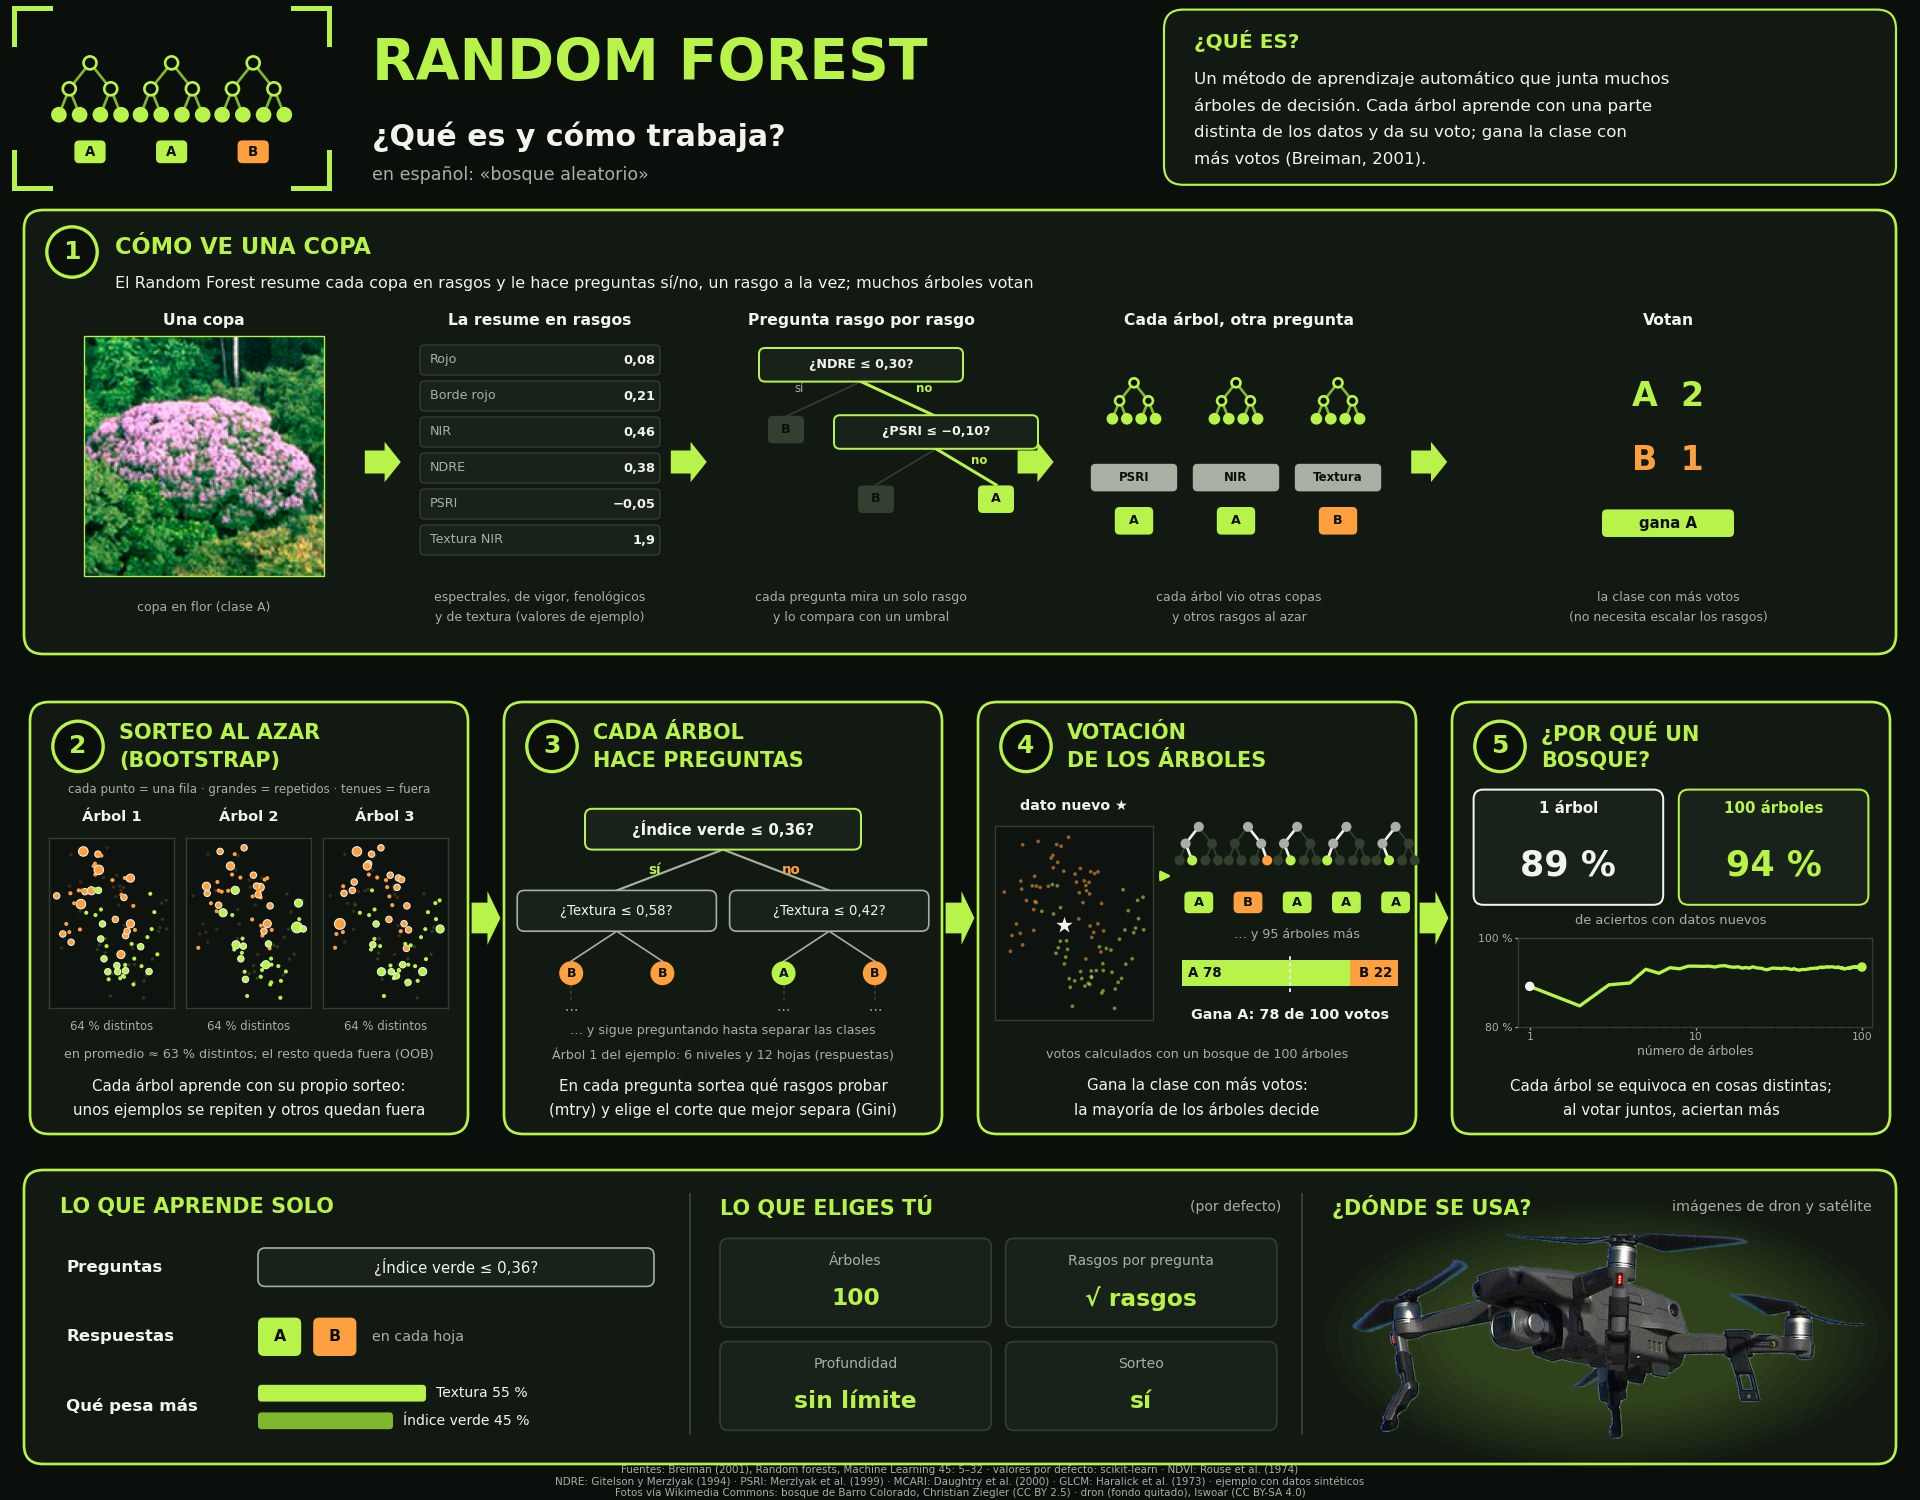

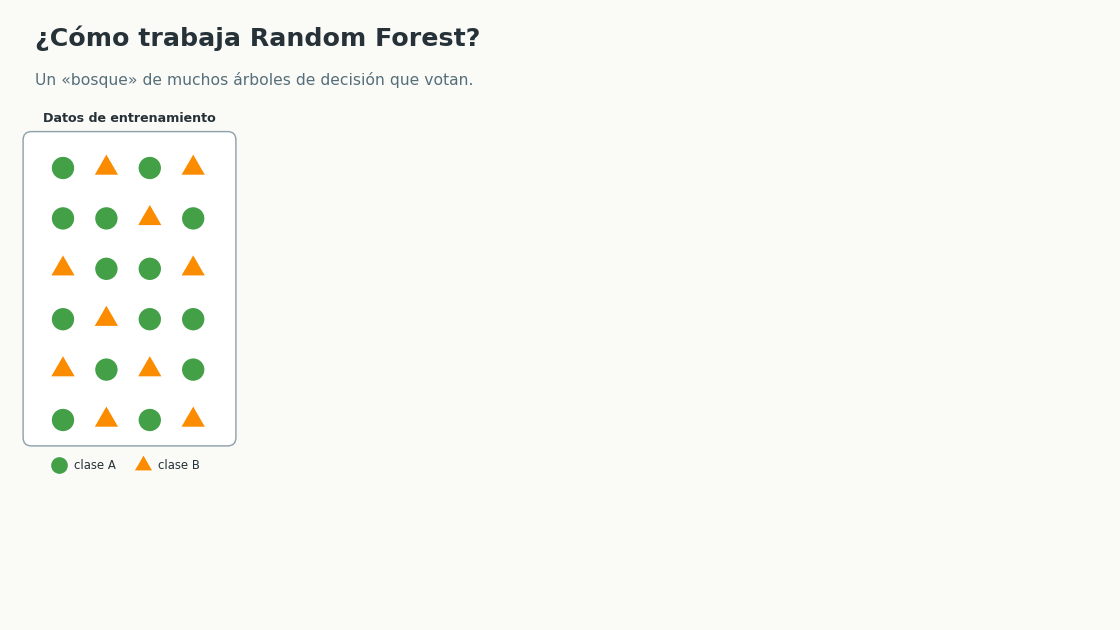

**Pasos:** **1** Conectar Drive y cargar las herramientas · **2** Rutas y parámetros · **3** Abrir el ortomosaico y ver tus polígonos · **4** Separar las copas (watershed) · **5** Etiquetar cada copa · **6** Medir cada copa (rasgos) · **7** Dividir: 70 % aprende, 30 % examen · **8** Elegir los rasgos que sirven · **9** Elegir mtry (validación cruzada) · **10** Entrenar el Random Forest · **11** Examen en el 30 % · **12** Guardar el modelo · **13** Detectar en todo el ortomosaico · **14** Mapa final (tú eliges el estilo) · **15** Ortomosaico interactivo con barra de umbral · **16** Guardar las copas del umbral que elegiste

**Cómo usarlo:** corre las celdas en orden con ▶. Solo se cambia el **Paso 2** (rutas y parámetros); el resto ya está listo.

## <font color="greenyellow" size="6"><b>PASO 1 · Conectar Drive y cargar las herramientas</b></font>
**Para qué:** que Colab lea tu ortomosaico y tus polígonos, y cargar las funciones de cada paso (archivo `topa_pasos.py` de tu Drive).  
**Qué verás:** «Mounted at /content/drive».

In [1]:
from google.colab import drive; drive.mount("/content/drive")
!pip install -q rasterio
import sys; sys.path.append("/content/drive/MyDrive/PASO_A_PASO")
from topa_pasos import *
estilo_figuras(tam_letra=11, fuente="DejaVu Sans")     # letra de TODAS las figuras: tamaño y tipo
# los colores se escriben con su nombre: verde, rojo, amarillo, azul, negro… (para verlos todos: ver_colores())

Mounted at /content/drive


## <font color="greenyellow" size="6"><b>PASO 2 · Rutas y parámetros</b></font>
**Para qué:** decir dónde están tus datos y dónde se guarda lo que salga. Es lo único que se cambia.

In [2]:
ORTO = "/content/drive/MyDrive/COLAB/vuelo 1_ortocorregido/imagen_prueba/ortomosaico_TOPA.tif"
SHP = "/content/drive/MyDrive/SHP_3/SHP_topa.shp"
CAMPO, TOPA = "ESPECIE", "1"                                   # campo de especie y valor que es topa
SALIDA = "/content/drive/MyDrive/PASO_A_PASO/RESULTADOS_RF"     # aquí quedan el modelo y el mapa

## <font color="greenyellow" size="6"><b>PASO 3 · Abrir el ortomosaico y ver tus polígonos</b></font>
**Para qué:** comprobar que los datos son los correctos antes de entrenar.  
**Qué verás:** el ortomosaico con tus topas (celeste) y otras especies (magenta), completo y acercado.

In [3]:
src = abrir_orto(ORTO)
shp = leer_poligonos(SHP, src, CAMPO, TOPA)
ZONA = zona_topas(shp)
ver_mapa(src, [capa(shp[shp.cl == 1], relleno="ninguno", borde="celeste", etiqueta="topa", grosor=0.6),
               capa(shp[shp.cl == 2], relleno="ninguno", borde="magenta", etiqueta="otras especies", grosor=0.6)],
         titulo="Tus polígonos", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha", zona=ZONA)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 4 · Separar las copas (watershed)</b></font>
**Para qué:** dividir el bosque en copas; cada copa será una muestra para el modelo.  
**Qué verás:** cuántas copas salieron y sus bordes amarillos sobre el ortomosaico.  
**Fuente:** copa mínima de 1 m²: Htun et al. (2026), p. 8. Los demás valores son los del Objetivo 1.

> NDVI_MIN = verdor mínimo · DIST_M = distancia mínima entre centros de copa · SIGMA_M = suavizado · HUECO_M2 = huecos que se rellenan · AREA = tamaño mínimo y máximo de copa.

In [4]:
COP, WS = copas_watershed(src, PIX_WS=0.05, WS_NDVI=0.25, WS_DIST_M=1.5, WS_SIGMA_M=0.15, WS_HUECO_M2=2, AREA_MIN_M2=1, AREA_MAX_M2=400)
ver_mapa(src, [capa(COP, relleno="ninguno", borde="amarillo", etiqueta="copas", grosor=0.6)],
         titulo="Copas del watershed", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha", zona=ZONA)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 5 · Etiquetar cada copa</b></font>
**Para qué:** darle a cada copa la clase del polígono con el que más se solapa; las copas sin polígono se toman como no topa.  
**Qué verás:** topa en verde, otras especies en rojo y copas sin polígono en gris.  
**Fuente:** clase por el área de mayor solape, sin contar solapes menores de 1 m²: Htun et al. (2026), p. 9.

In [5]:
GEO = etiquetar_copas(COP, shp, SOLAPE_MIN_M2=1)
ver_mapa(src, capas_etiquetas(GEO, topa="verde", otras="rojo", fondo="gris", borde="negro", grosor=0.2, transparencia=0.9),
         titulo="Clase de cada copa", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha", zona=ZONA)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 6 · Medir cada copa (rasgos)</b></font>
**Para qué:** sacar los números de cada copa: mediana y variación de 7 bandas y 8 índices, y 5 medidas de textura del infrarrojo.  
**Qué verás:** la tabla con los primeros rasgos y el NDVI de cada copa pintado sobre el ortomosaico. Tarda unos minutos.  
**Fuente:** mediana y desviación, textura con 32 niveles: Ramanamandimby et al. (2026), p. 8.


4027 copas con 35 rasgos (0 excluidas por datos incompletos) · 474 s


,B1_med,B1_std,B2_med,B2_std,B3_med,B3_std,G_med,G_std,R_med,R_std,...,PSRI_std,GRNDVI_med,GRNDVI_std,GLCM_contrast_NIR,GLCM_dissimilarity_NIR,GLCM_homogeneity_NIR,GLCM_correlation_NIR,GLCM_ASM_NIR,y,tipo
43,18294.0,20141.263672,22952.0,19829.843750,6295.0,13965.542969,1034.5,1202.924561,486.0,756.309875,...,0.039667,0.719404,0.132874,3.544990,1.278984,0.549444,0.965095,0.008702,0,otras
47,20723.0,14216.108398,26353.5,14181.604492,8581.0,11199.730469,1151.0,705.617310,667.5,402.224609,...,0.053859,0.630218,0.101228,2.318311,1.053438,0.587839,0.966424,0.011181,0,otras
56,14479.5,18306.009766,19288.5,17944.529297,6217.5,12159.882812,694.0,847.764954,331.0,540.992676,...,0.034452,0.779602,0.085838,1.841336,0.843753,0.665946,0.985455,0.021232,1,topa
70,17476.0,17219.802734,21767.0,16572.103516,8347.0,13281.689453,788.0,816.998230,387.0,516.232361,...,0.040676,0.740864,0.107567,2.668721,1.068296,0.601833,0.974833,0.016008,1,topa
86,8981.0,15334.025391,16304.0,15804.020508,5235.5,13117.713867,783.0,805.124329,304.0,425.896393,...,0.032553,0.819925,0.097046,1.013933,0.646925,0.712296,0.990517,0.026872,0,otras


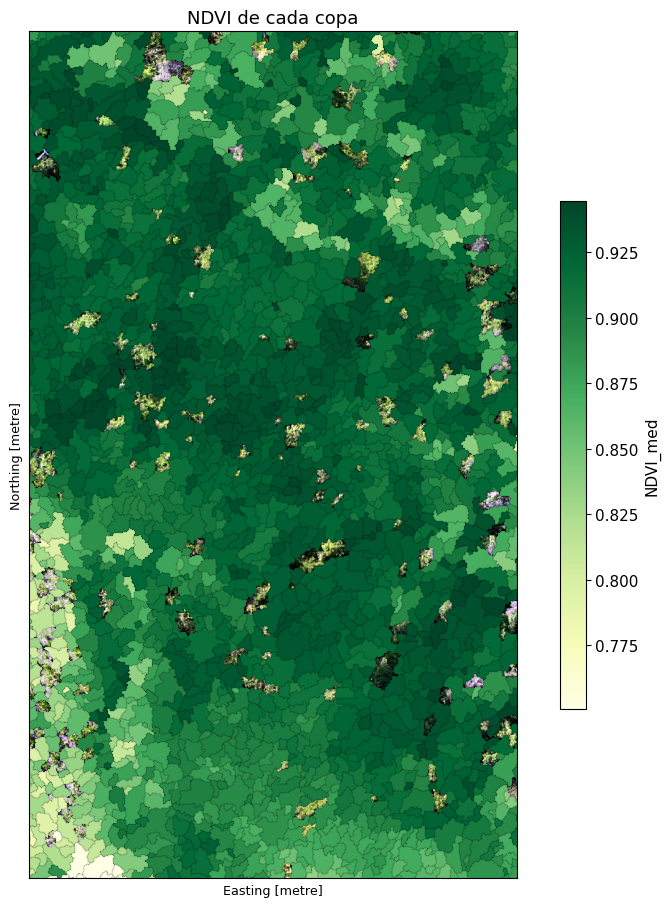

In [6]:
DATOS, RAS0 = calcular_rasgos(src, GEO, GLCM_NIVELES=32)
display(DATOS.head())
ver_rasgo(src, GEO, DATOS, "NDVI_med", titulo="NDVI de cada copa", tam_titulo=13, colores="amarillo a verde", borde="negro", grosor=0.1, zona=ZONA)

## <font color="greenyellow" size="6"><b>PASO 7 · Dividir: 70 % aprende, 30 % examen</b></font>
**Para qué:** separar las copas en dos zonas con una línea: con el 70 % aprende y con el 30 % se examina.  
**Qué verás:** cuántas copas de cada clase quedan a cada lado y el mapa con la línea de corte.  
**Fuente:** corte espacial por el centro de cada copa: Htun et al. (2026), pp. 8 y 10. El 70/30 es del proyecto.

In [7]:
TR, TE, es_examen, EJE, SV = corte_espacial(shp, GEO, DATOS, PRUEBA=0.30)
ver_mapa(src, capas_corte(GEO, TR, TE, aprende="azul", examen="naranja", borde="negro", grosor=0.2),
         titulo="70 % aprende (azul) · 30 % examen (naranja)", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha",
         linea=(EJE, SV), color_linea="rojo", grosor_linea=2)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 8 · Elegir los rasgos que sirven</b></font>
**Para qué:** quedarse solo con los rasgos que separan topa de no topa y quitar los repetidos (solo con el 70 %).  
**Qué verás:** una barra por rasgo: verde entra, naranja repite a otro, gris no separa.  
**Fuente:** Kruskal-Wallis + Benjamini-Hochberg (p < 0,05) y Spearman 0,80: Ramanamandimby et al. (2026), p. 9.

35 rasgos → 32 separan las clases → 15 sin repetidos: RE_std, MCARI_med, GNDVI_med, GLCM_contrast_NIR, MCARI_std, B1_std, PSRI_med, GLCM_correlation_NIR, NDRE_std, B1_med, GNDVI_std, NIR_med, R_std, PSRI_std, B3_std


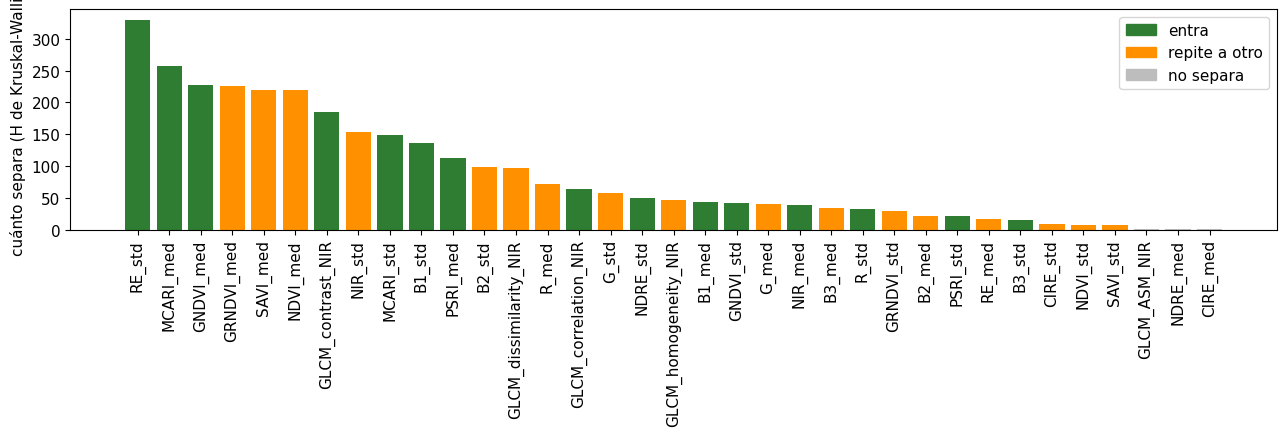

In [8]:
SEL = seleccionar_rasgos(TR, RAS0, ALFA_FDR=0.05, RHO_MAX=0.80)

## <font color="greenyellow" size="6"><b>PASO 9 · Elegir mtry (validación cruzada)</b></font>
**Para qué:** probar cuántos rasgos mira cada pregunta de los árboles y quedarse con el que da mejor Kappa (solo con el 70 %).  
**Qué verás:** el Kappa de cada mtry; la estrella es el elegido. Es el paso más largo.  
**Fuente:** 1000 árboles y validación cruzada 5 × 5 por Kappa: Ramanamandimby et al. (2026), p. 9.

Buscando mtry entre 1 y 15 con 5 × 5 pliegues y 1000 árboles (puede tardar)…


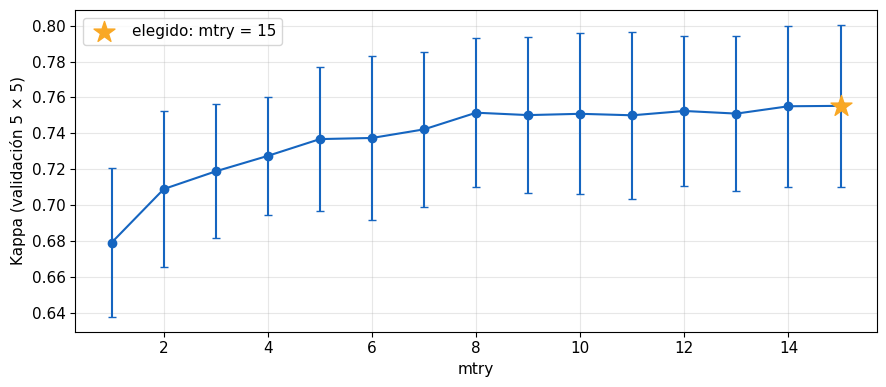

mtry = 15 · Kappa en validación 0.755 ± 0.045


In [9]:
MTRY, K_CV = buscar_mtry(TR, SEL, ARBOLES=1000, PLIEGUES=5, REPETICIONES=5)

## <font color="greenyellow" size="6"><b>PASO 10 · Entrenar el Random Forest</b></font>
**Para qué:** entrenar el bosque UNA sola vez con el 70 % y ver qué rasgos usó más.  
**Qué verás:** una barra por rasgo: cuánto cae el acierto si se desordena ese rasgo.  
**Fuente:** un solo entrenamiento con el 70 %: Ramanamandimby et al. (2026), p. 9. Importancia por permutación: Sivanandam y Lucieer (2022).

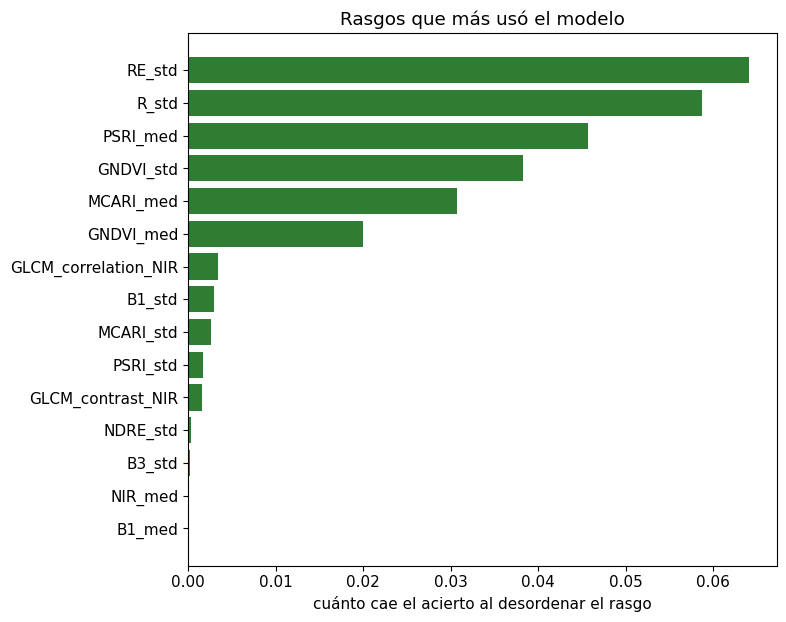

In [10]:
rf, IMP = entrenar_rf(TR, SEL, ARBOLES=1000, MTRY=MTRY)

## <font color="greenyellow" size="6"><b>PASO 11 · Examen en el 30 %</b></font>
**Para qué:** medir qué tan bien reconoce la topa en copas que nunca vio.  
**Qué verás:** la tabla de métricas con su intervalo de confianza del 95 %, la matriz de confusión, la curva ROC y el mapa de aciertos y errores.  
**Fuente:** clase por voto de mayoría de los árboles: Shamaoma et al. (2023), p. 8. Intervalos por bootstrap (1000 remuestreos).

In [11]:
TAB, MATRIZ, y_p = evaluar(rf, TE, SEL, N_BOOT=1000)
display(TAB)
ver_mapa(src, capas_examen(GEO, TR, TE, y_p, aprendio="azul", acierto="verde", falsa_alarma="rojo", no_reconocida="naranja"),
         titulo=f"Examen en el 30 % · Kappa {TAB.loc['Kappa', 'valor']:.3f}", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha",
         linea=(EJE, SV), color_linea="rojo")

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 12 · Guardar el modelo</b></font>
**Para qué:** guardar el MISMO modelo que rindió el examen, con todo lo que necesita el detector.  
**Qué verás:** la ruta del modelo guardado.  
**Fuente:** no se vuelve a entrenar con el 100 %: Htun et al. (2026), p. 11.

In [12]:
MODELO = guardar_modelo(f"{SALIDA}/rf_topa_fuentes.joblib", rf, SEL, WS, src.res[0], {
    "rf": {"arboles": 1000, "mtry": MTRY, "kappa_cv": K_CV, "semilla": 42}, "corte": {"eje": EJE, "valor": SV, "prueba": 0.30},
    "etiquetado": {"solape_min_m2": 1, "sin_poligono": "no topa"}, "metricas_30": TAB.to_dict(), "matriz_30": MATRIZ, "importancia": IMP.to_dict(),
    "muestras": DATOS.assign(grupo=np.where(es_examen, "test", "train")), "rasgos_todos": RAS0,
    "fuentes": ["Ramanamandimby et al. 2026, Geomatics 6:118", "Htun et al. 2026, Geomatics 6:113"]})

Modelo guardado: /content/drive/MyDrive/PASO_A_PASO/RESULTADOS_RF/rf_topa_fuentes.joblib (13.4 MB)


## <font color="greenyellow" size="6"><b>PASO 13 · Detectar en todo el ortomosaico</b></font>
**Para qué:** correr el modelo en todo el ortomosaico y guardar sus copas de topa con su probabilidad.  
**Qué verás:** cuántas copas de topa encontró. Tarda varios minutos.  
**Fuente:** clase que da el modelo con umbral de decisión 0,50 (tutorial de Esri). Copa entera del watershed.

> Para usar el modelo de la tesis en vez del recién entrenado, antes de esta celda escribe: MODELO = "/content/drive/MyDrive/RF_FUENTES/rf_topa_fuentes.joblib"

In [13]:
TOP, SHP_TOPA = detectar(MODELO, ORTO, SALIDA)

Corriendo el modelo en todo el ortomosaico (puede tardar varios minutos)…
Modelo rf_topa_fuentes · tipo ML · orto ortomosaico_TOPA · forma mascaras
Modelo rf_topa_fuentes · topa = clase 1 · bandas {'B': 3, 'G': 4, 'R': 5, 'RE': 6, 'NIR': 7}
Separando copas…
Forma «copa entera»: uso las 1419 copas de todo ortomosaico_TOPA ya hechas (/content/drive/MyDrive/COLAB/vuelo 1_ortocorregido/imagen_prueba/copas_entera_ortomosaico_TOPA_d3_a22-79.25.gpkg)
   379 topas del modelo → 379 con forma de copa entera del watershed: 85 con las copas que tienen más de la mitad dentro · 294 con la copa donde cae la mayor parte · 0 fuera de la segmentación (como las marcó el modelo) · 204 caen en las mismas copas que otra detección (quedan una encima de otra)
   un polígono por copa: 379 detecciones → 176 copas de topa (n_detecc = cuántas detecciones cayeron en cada copa)
   segmentación de todo ortomosaico_TOPA: 1419 copas (176 topa y 1243 otras), cada una con su centroide y sus coordenadas x_centro, y_centr

## <font color="greenyellow" size="6"><b>PASO 14 · Mapa final (tú eliges el estilo)</b></font>
**Para qué:** dibujar el mapa de presentación. Cambia los valores para elegir el título, las letras, los colores, la leyenda y lo demás.  
**Qué verás:** el mapa con marco, coordenadas en los 4 lados, escala, norte y leyenda; queda guardado en SALIDA. Si solo cambias el estilo, corre esta celda otra vez (no hace falta detectar de nuevo).

> Colores: escríbelos con su nombre en español (verde, rojo, rojo vivo, amarillo, naranja, azul, celeste, morado, rosado, marrón, gris, negro, blanco…) o en inglés (green, red, black…); «ninguno» = sin relleno. Para ver todos los colores: ver_colores(). Lugar de la leyenda: «arriba derecha», «arriba izquierda», «abajo derecha», «abajo izquierda» o «centro». Transparencia: de 0 (invisible) a 1 (opaco).

In [3]:
SHP_TOPA = f"{SALIDA}/topa_rf_topa_fuentes_ortomosaico_TOPA_ws_esri.shp"   # tus copas detectadas
TOP = gpd.read_file(SHP_TOPA)
mapa_final(ORTO, TOP, "Random Forest", SALIDA,
           titulo="Detección de", especie="Ochroma pyramidale", tam_titulo=13,
           relleno="rojo", transparencia=0.45, borde="amarillo", grosor=0.7,
           titulo_leyenda=None, tam_leyenda=9, pos_leyenda="abajo derecha",
           norte=True, tam_norte=0.6, pos_norte="arriba derecha", fondo_norte="blanco",
           escala=True, largo_escala=None, tramos_escala=4, tam_escala=1.0, pos_escala="abajo izquierda",
           coordenadas=True, tam_coord=8, cada_coord=None, lados_coord="cuatro", sistema=True,
           tam_letra=8, color_marco="negro", ancho=9, dpi=300)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 15 · Ortomosaico interactivo con barra de umbral</b></font>
**Para qué:** mover y acercar el ortomosaico con el ratón y mover la barra de umbral: se ven las copas con probabilidad mayor que el umbral y cuántas son.  
**Qué verás:** la página interactiva. En 0,50 marca las mismas copas que el mapa final. Al pasar el ratón sobre una copa se ve su probabilidad; la otra barra aclara el ortomosaico.

In [15]:
mapa_interactivo(ORTO, SHP_TOPA, umbral=0.50, titulo="Detección de Ochroma pyramidale",
                 relleno="rojo vivo", borde="blanco", transparencia=0.40, grosor=1.2, tam_letra=14, alto=650)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 16 · Guardar las copas del umbral que elegiste</b></font>
**Para qué:** guardar en un SHP (para ArcGIS o QGIS) las copas con probabilidad mayor que el umbral que elegiste en la barra.  
**Qué verás:** cuántas copas pasaron el umbral y dónde quedó el SHP.

> Para el mapa de presentación con ese umbral: mapa_final(ORTO, TOP_U, "Random Forest", SALIDA, titulo="Detección de", relleno="rojo")

In [ ]:
TOP_U, SHP_U = guardar_umbral(SHP_TOPA, umbral=0.50)      # pon aquí el umbral que elegiste en la barra